# Sanity checks

Step 2 of the [roadmap](../ROADMAP.md). Before the training is tuned (step 4) or features are added (step 5), these checks make sure that the pipeline does what we think it does. Errors in the alignment of the data or in the model do not crash: they only make the results too good (leakage) or too bad, and no amount of tuning finds them later.

**Task (step 0):** at 12:00 on day D-1 the 24 hourly prices of day D are forecast. There is one window per day: the history ends at midnight before D, the targets are the hours 00 to 23 of D. The measured weather of day D (`wind_mean`, `solar_mean`) is used as a perfect day-ahead forecast, so all results are an upper bound for real forecasts.

Only the training and validation splits are used, the test split stays untouched.

**This notebook documents step 2 as it was run.** Its outputs show the state of that time: the six base features and the LSTM trained for it, a run that is no longer kept. With the current `configs/lstm.toml` (the features selected in step 5) a new run gives other numbers.

In [1]:
import contextlib
import copy
import io

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from spotforecast.config import load_config
from spotforecast.data.dataset import load_datasets, split_history_future_batch_transform
from spotforecast.data.features import get_input_feature_names
from spotforecast.evaluate import compute_metrics, latest_run, load_run, predict
from spotforecast.models.baselines import fit_ridge, naive_forecasts, ridge_features, stack_windows
from spotforecast.models.lstm import build_model

device = torch.device("cpu")
config = load_config("lstm")
# the preprocessing log is long, python -m spotforecast.train prints it
with contextlib.redirect_stdout(io.StringIO()):
    train_ds, valid_ds, _ = load_datasets(config, load_config("data"))  # the test split is not used here
X_train, Y_train = stack_windows(train_ds)
X_val, Y_val = stack_windows(valid_ds)
splits = {"train": (train_ds, X_train, Y_train), "val": (valid_ds, X_val, Y_val)}
feature_names = get_input_feature_names(config["features"])


def unscale(values, col=0):
    # undoes the scaling of target column col: 0 is the spot price in EUR/MWh, then the future covariates
    return values * valid_ds.target_scaler.scale_[col] + valid_ds.target_scaler.mean_[col]


print(f"{len(train_ds)} training days, {len(valid_ds)} validation days")
print(f"history {X_val.shape[1:]}: {feature_names}")
print(f"targets {Y_val.shape[1:]}: {config['targets']}")

628 training days, 91 validation days
history (192, 10): ['Spot', 'solar', 'solar_mean', 'wind_mean', 'onshore wind', 'solar capacity', 'Spot_roll_168', 'solar_util', 'hour_sin', 'hour_cos']
targets (24, 3): ['Spot', 'wind_mean', 'solar_mean']


## 1. Alignment of history, targets and time

**Why:** The windows are cut out of one long table by index arithmetic. An off-by-one shifts the targets by an hour against the history: the model then either sees part of the answer (leakage, results too good) or learns a shifted target (results too bad). The new day windows add two more ways to get it wrong: the day boundaries and the clock changes.

**Passes if:**
- a) The spot price in the features and in the targets is identical row by row, because both are scaled with the same training statistics.
- b) The 24 targets of every window are the spot prices of the 24 rows right after its history.
- c) The last history hour is 23:00 and the first target hour 00:00, read from the data itself (`hour_sin`, `hour_cos`) and from the timestamps. Every forecast day has 24 hours, and only the days with a clock change are missing.
- d) The solar values peak around midday and are about 0 at night, both in the weather of day D and in the measured solar generation of the history. A shifted peak would mean that a series is misaligned, e.g. by a time zone.

In [2]:
for name, (ds, X, Y) in splits.items():
    # a) the same series in the features and in the targets
    diff_rows = (ds.features[:, 0] - ds.target[:, 0]).abs().max().item()
    # b) computed from the row indices, independently of EnergyDataset.__getitem__
    target_rows = ds.usable_idxs[:, None] + ds.window + np.arange(ds.horizon)
    diff_windows = np.abs(ds.features.numpy()[target_rows, 0] - Y[:, :, 0]).max()
    print(f"{name}: largest difference per row {diff_rows:.1e}, per window {diff_windows:.1e}")
    assert diff_rows < 1e-5 and diff_windows < 1e-5

train: largest difference per row 0.0e+00, per window 0.0e+00
val: largest difference per row 0.0e+00, per window 0.0e+00


In [3]:
hour_cols = [feature_names.index("hour_sin"), feature_names.index("hour_cos")]


def hour_from_features(x):
    # hour of the day recovered from its cyclic encoding
    return (np.round(np.arctan2(x[..., 0], x[..., 1]) * 24 / (2 * np.pi)) % 24).astype(int)


for name, (ds, X, Y) in splits.items():
    last_history_hour = hour_from_features(X[:, -1, hour_cols])
    first_target_hour = hour_from_features(ds.features.numpy()[ds.usable_idxs + ds.window][:, hour_cols])
    starts = ds.forecast_starts()
    history_end = ds.dates[ds.usable_idxs + ds.window - 1]
    target_end = ds.dates[ds.usable_idxs + ds.window + ds.horizon - 1]
    all_days = pd.date_range(starts[0].date(), starts[-1].date(), freq="D")
    skipped = all_days.difference(pd.DatetimeIndex(starts.date))

    print(f"{name}: last history hour {set(last_history_hour)}, first target hour {set(first_target_hour)}, "
          f"forecast days start at {set(starts.hour)}:00, the last target is at {set(target_end.hour)}:00 of the same day")
    print(f"       days without a forecast: {[d.date().isoformat() for d in skipped]}")
    assert set(last_history_hour) == {23} and set(first_target_hour) == {0} and set(starts.hour) == {0}
    assert ((starts - history_end) == pd.Timedelta("1h")).all()
    assert (target_end.date == starts.date).all() and set(target_end.hour) == {23}

train: last history hour {np.int64(23)}, first target hour {np.int64(0)}, forecast days start at {0}:00, the last target is at {23}:00 of the same day
       days without a forecast: ['2023-03-26', '2023-10-29', '2024-03-31']
val: last history hour {np.int64(23)}, first target hour {np.int64(0)}, forecast days start at {0}:00, the last target is at {23}:00 of the same day
       days without a forecast: ['2024-10-27']


train: solar weather of day D peaks at 13:00, solar generation of D-1 at 12:00; night (22:00 to 04:00) relative to the peak: 0.000
val: solar weather of day D peaks at 12:00, solar generation of D-1 at 12:00; night (22:00 to 04:00) relative to the peak: -0.000


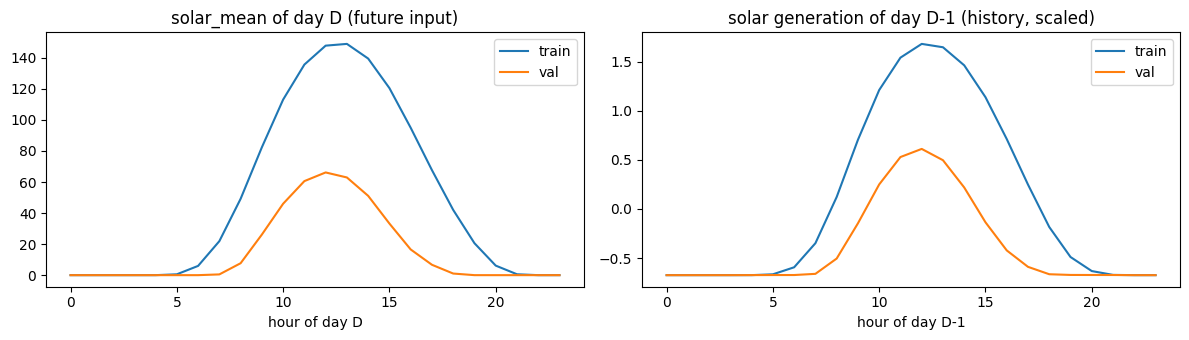

In [4]:
solar_col = config["targets"].index("solar_mean")
solar_gen_col = feature_names.index("solar")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, (ds, X, Y) in splits.items():
    weather = unscale(Y[:, :, solar_col], solar_col).mean(axis=0)
    # the history has 8 full days that end at 23:00, so its last 24 rows are the hours 0 to 23 of day D-1
    generation = X[:, -24:, solar_gen_col].mean(axis=0)
    axes[0].plot(weather, label=name)
    axes[1].plot(generation, label=name)
    print(f"{name}: solar weather of day D peaks at {weather.argmax()}:00, solar generation of D-1 at {generation.argmax()}:00; "
          f"night (22:00 to 04:00) relative to the peak: {weather[[22, 23, 0, 1, 2, 3, 4]].max() / weather.max():.3f}")
axes[0].set(title="solar_mean of day D (future input)", xlabel="hour of day D")
axes[1].set(title="solar generation of day D-1 (history, scaled)", xlabel="hour of day D-1")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Result: passed.**
- The spot price in the features and in the targets is identical (largest difference 0), also per window.
- Every history ends at 23:00, every target starts at 00:00 and ends at 23:00 of the same day. Only the days with a clock change are missing: 2023-03-26, 2023-10-29 and 2024-03-31 in train, 2024-10-27 in val.
- The solar weather of day D peaks at 12:00 to 13:00 and is 0 at night, the measured solar generation of D-1 peaks at 12:00. Weather and history are on the same clock.

## 2. Model start and overfitting a single batch

**Why:** The model forecasts the last known price plus a learned deviation. Untrained, the deviations should be small, so its error should be close to that of persistence (repeating the price of 23:00). A much larger start error means that the initialization of the head produces large deviations that the training first has to undo.

The overfit test is the standard check for the model and the training loop together: a working network can memorize 64 days almost perfectly. If it cannot, the gradients do not arrive or the shapes do not match. A shape mismatch such as (64, 24) against (64, 24, 1) broadcasts silently into a wrong loss.

**Passes if:** the start MSE is in the order of the persistence MSE, `pred.shape == y.shape`, and the loss falls below about 0.01 within 500 steps.

In [5]:
overfit_config = copy.deepcopy(config)
overfit_config["net_params"]["dropout_p"] = 0.0  # dropout would keep the training loss from reaching 0
model_check = build_model(overfit_config, X_train.shape[-1], Y_train.shape[-1] - 1, rng=torch.Generator().manual_seed(1)).to(device)

# a fixed batch: the first 64 training days
x_batch, y_batch = split_history_future_batch_transform(torch.from_numpy(X_train[:64]), torch.from_numpy(Y_train[:64]), device, train=False)

model_check.eval()
with torch.no_grad():
    pred = model_check(x_batch)
persistence = x_batch[0][:, -1:, 0].expand_as(y_batch)
print(f"shapes: pred {tuple(pred.shape)}, y {tuple(y_batch.shape)}")
assert pred.shape == y_batch.shape
print(f"untrained model MSE {torch.mean((pred - y_batch) ** 2).item():.3f}, "
      f"persistence MSE {torch.mean((persistence - y_batch) ** 2).item():.3f} (scaled)")

shapes: pred (64, 24), y (64, 24)
untrained model MSE 3.374, persistence MSE 0.996 (scaled)


In [6]:
torch.manual_seed(1)
optimizer = torch.optim.AdamW(model_check.parameters(), lr=1e-3, weight_decay=0.0)
criterion = torch.nn.MSELoss()
model_check.train()
for step in range(1, 501):
    optimizer.zero_grad()
    loss = criterion(model_check(x_batch), y_batch)
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step}: loss {loss.item():.4f}")

step 50: loss 0.2011
step 100: loss 0.1359
step 150: loss 0.0585
step 200: loss 0.0211
step 250: loss 0.0089
step 300: loss 0.0028
step 350: loss 0.0011
step 400: loss 0.0006
step 450: loss 0.0003
step 500: loss 0.0002


**Result: passed, with one finding.**
- The shapes match, (64, 24) for both.
- The model memorizes the batch: the loss is below 0.01 after 250 steps and at 0.0002 after 500. Model, gradients and training loop work.
- **Finding:** the untrained model starts with an MSE of 3.37, more than three times the persistence MSE (1.00) and about as bad as forecasting the mean (3.52). The initialization of the head produces large deviations from the last price that the training first has to undo. For step 4: initialize the last layer close to 0, so that the model starts at persistence.

## 3. Forecasts of the trained model on single days

**Why:** A mean error does not show *how* a model is wrong. Single days show whether the LSTM follows the shape of the day (morning and evening peak, the solar dip at midday), whether it is too smooth (close to an average day, typical for a model that learns too little) and whether it is shifted in time. Ridge, with the same inputs, is the bar to beat.

The run is the LSTM trained locally with the config of that time (seed 1). It also gives the first numbers of the new task; the reference with 3 seeds is step 3.

**Passes if:** the forecasts have the shape of a day and are not shifted. How good they are is decided in steps 3 and 4.

In [7]:
run = latest_run()
model, run_config = load_run(run, device)
# a run of the old 48 h task does not fit the day windows
assert all(run_config[k] == config[k] for k in ["features", "targets", "forecast_history", "forecast_horizon"]), run
print(f"run {run}\n")

ridge = fit_ridge(train_ds)
pred_lstm, y_val = predict(model, valid_ds, device)
pred_ridge = ridge.predict(ridge_features(X_val, Y_val))
forecasts = {**naive_forecasts(X_val, y_val.shape[1]), "ridge": pred_ridge, "lstm": pred_lstm}
table = pd.DataFrame({name: compute_metrics(pred, y_val, valid_ds) for name, pred in forecasts.items()}).T
print("validation split, errors in EUR/MWh")
print(table.round(2).to_string())

# underfitting check from the 48 h runs: does the LSTM fit the training days at least as well as Ridge?
train_lstm = compute_metrics(*predict(model, train_ds, device), train_ds)["mae_eur"]
train_ridge = compute_metrics(ridge.predict(ridge_features(X_train, Y_train)), Y_train[:, :, 0], train_ds)["mae_eur"]
print(f"\ntraining split MAE: LSTM {train_lstm:.1f}, Ridge {train_ridge:.1f} EUR/MWh")

run energy_lstm_20261029-124837_seed1

validation split, errors in EUR/MWh
             mse_z  mae_eur  rmse_eur  mae_eur_00-06  mae_eur_06-12  mae_eur_12-18  mae_eur_18-24
mean          3.52    41.42     73.36          26.79          43.63          50.98          44.27
persistence   2.88    34.64     66.35          11.14          37.24          46.98          43.22
day D-1       2.58    37.85     62.89          24.90          41.64          46.35          38.53
day D-7       4.90    47.10     86.60          35.49          49.61          57.80          45.51
ridge         1.71    24.35     51.16          13.44          26.14          31.57          26.24
lstm          1.89    24.52     53.82           8.69          28.18          33.97          27.24

training split MAE: LSTM 17.6, Ridge 16.7 EUR/MWh


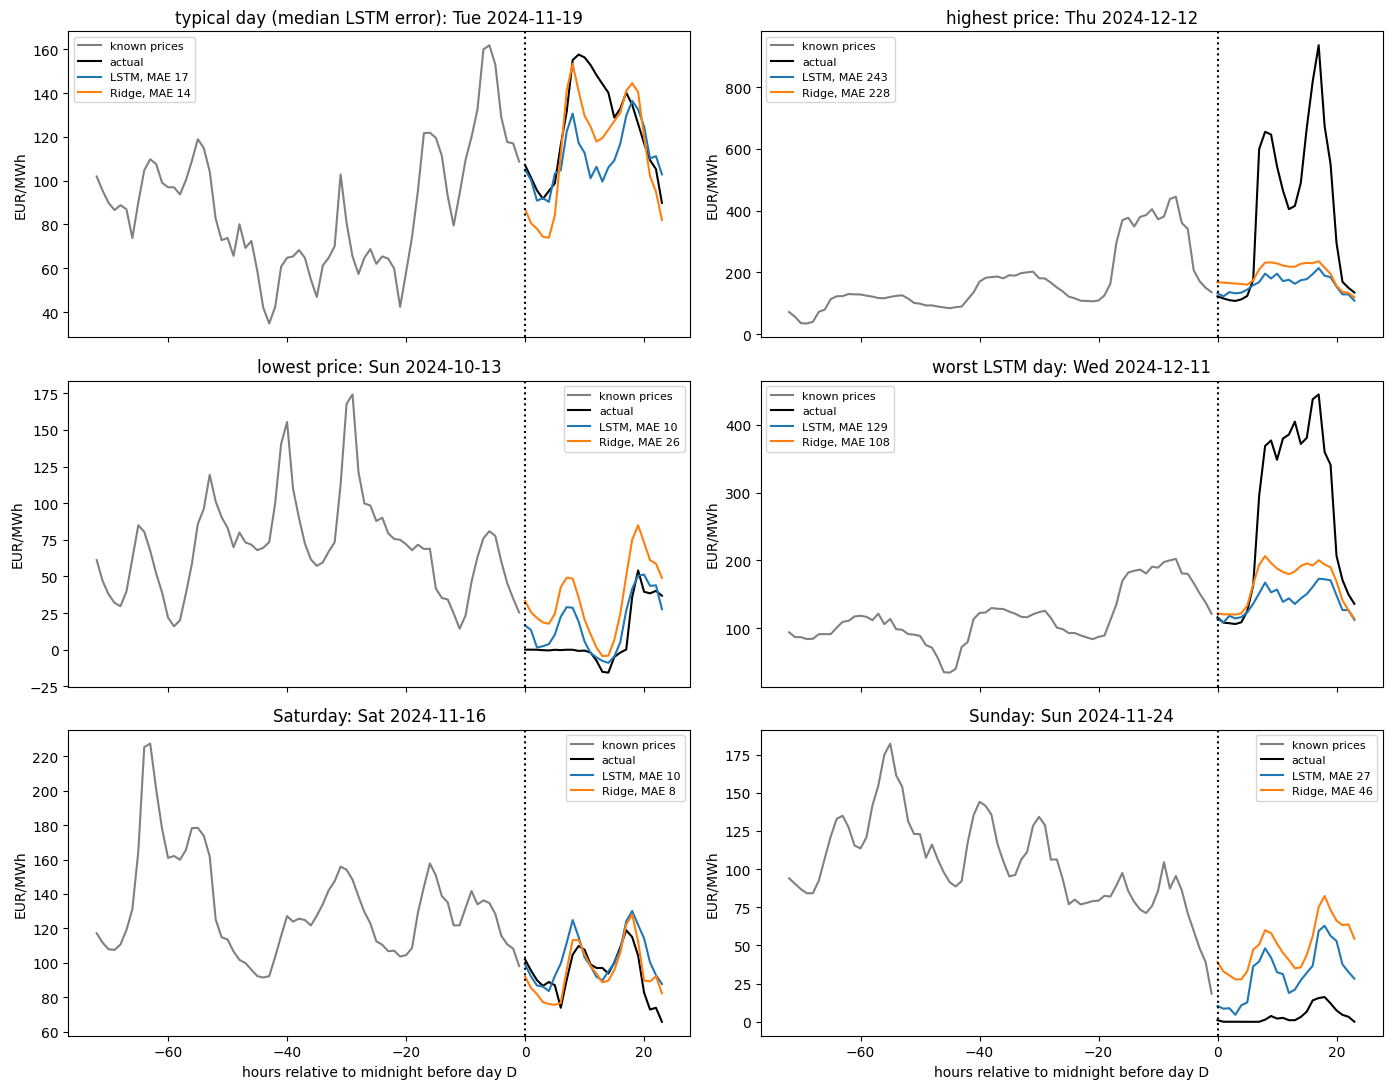

mean price range within a day: actual 118, LSTM 63, Ridge 85 EUR/MWh


In [8]:
days = valid_ds.forecast_starts()
y_eur, lstm_eur, ridge_eur = unscale(y_val), unscale(pred_lstm), unscale(pred_ridge)
history_eur = unscale(X_val[:, -72:, 0])  # the spot history is scaled like the target (check 1a)
lstm_mae = np.abs(lstm_eur - y_eur).mean(axis=1)

# in this order, each day is shown only once
candidates = {
    "typical day (median LSTM error)": [np.argsort(lstm_mae)[len(lstm_mae) // 2]],
    "highest price": [np.argmax(y_eur.max(axis=1))],
    "lowest price": [np.argmin(y_eur.min(axis=1))],
    "worst LSTM day": np.argsort(lstm_mae)[::-1],
    "Saturday": np.flatnonzero(days.dayofweek == 5)[6:],
    "Sunday": np.flatnonzero(days.dayofweek == 6)[6:],
}
picks = {}
for title, idxs in candidates.items():
    picks[title] = next(i for i in idxs if i not in picks.values())

fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
for ax, (title, i) in zip(axes.flat, picks.items()):
    ax.plot(np.arange(-72, 0), history_eur[i], color="grey", label="known prices")
    ax.plot(np.arange(24), y_eur[i], color="black", label="actual")
    ax.plot(np.arange(24), lstm_eur[i], label=f"LSTM, MAE {lstm_mae[i]:.0f}")
    ax.plot(np.arange(24), ridge_eur[i], label=f"Ridge, MAE {np.abs(ridge_eur[i] - y_eur[i]).mean():.0f}")
    ax.axvline(0, color="black", linestyle=":")
    ax.set_title(f"{title}: {days[i]:%a %Y-%m-%d}")
    ax.set_ylabel("EUR/MWh")
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("hours relative to midnight before day D")
plt.tight_layout()
plt.show()

# too smooth? compare the price range within a day
print(f"mean price range within a day: actual {np.ptp(y_eur, axis=1).mean():.0f}, "
      f"LSTM {np.ptp(lstm_eur, axis=1).mean():.0f}, Ridge {np.ptp(ridge_eur, axis=1).mean():.0f} EUR/MWh")

**Result: passed, with findings.** The forecasts have the shape of a day (morning and evening peak, the dip at midday) and are not shifted in time.
- **LSTM and Ridge are equal** on the validation split: MAE 24.5 and 24.4 EUR/MWh. The LSTM is much better at night (00 to 06: 8.7 against 13.4), because it starts from the last known price, and worse during the day (06 to 18).
- **The LSTM is too smooth.** Within a day its forecasts span 63 EUR/MWh on average, the actual prices 118, Ridge 85. On the training days it is also worse than Ridge (MAE 17.6 against 16.7), so it still underfits.
- **The training is not finished.** The best epoch was the last one (70), and the learning rate was already down to 2.5e-5. With 628 days an epoch has only 10 update steps, 700 in total, about 12 times fewer than with the old 48 h windows. For step 4.
- **Neither model foresees the price spikes** of 11 and 12 December 2024 (Dunkelflaute, up to 936 EUR/MWh). Both stay between 150 and 230.

## 4. Does the LSTM use the weather of day D?

**Why:** Because of the decision in step 0, the measured weather of day D is the strongest input: in the 48 h setting it improved Ridge from 35.1 to 25.7 EUR/MWh. The LSTM gets it only in the head, next to the last state of the LSTM. If the model ignored it, it would waste the most valuable information.

Test: the weather of day D is shuffled between the days. The values stay realistic but belong to another day, so a model that uses them gets clearly worse.

**Passes if:** the LSTM loses about as much as Ridge, or more.

In [9]:
def lstm_forecast(X, Y):
    x, _ = split_history_future_batch_transform(torch.from_numpy(X), torch.from_numpy(Y), device, train=False)
    model.eval()
    with torch.no_grad():
        return model(x).numpy()


def mae_eur(pred):
    return np.abs(unscale(pred) - unscale(y_val)).mean()


rng = np.random.default_rng(1)
shuffled = {"LSTM": [], "Ridge": []}
for _ in range(10):
    Y_shuffled = Y_val.copy()
    Y_shuffled[:, :, 1:] = Y_val[rng.permutation(len(Y_val)), :, 1:]
    shuffled["LSTM"].append(mae_eur(lstm_forecast(X_val, Y_shuffled)))
    shuffled["Ridge"].append(mae_eur(ridge.predict(ridge_features(X_val, Y_shuffled))))

normal = {"LSTM": mae_eur(lstm_forecast(X_val, Y_val)), "Ridge": mae_eur(pred_ridge)}
for name in normal:
    print(f"{name}: MAE {normal[name]:.1f} with the weather of the day, {np.mean(shuffled[name]):.1f} with shuffled weather "
          f"(+{np.mean(shuffled[name]) - normal[name]:.1f} EUR/MWh)")

LSTM: MAE 24.5 with the weather of the day, 29.7 with shuffled weather (+5.1 EUR/MWh)
Ridge: MAE 24.4 with the weather of the day, 34.9 with shuffled weather (+10.5 EUR/MWh)


**Result: not passed.** With shuffled weather the LSTM gets 5.1 EUR/MWh worse, Ridge 10.5. The LSTM uses the weather of day D, but only half as much as the linear model. Possible reasons for step 4: the weather only enters the head, as 48 flat numbers next to 256 values from the LSTM, behind a dropout of 0.5, and the training is short.

## 5. Bidirectional readout

**Why:** In a bidirectional LSTM, the output of the backward direction at the last time step has seen only that one hour. At the time of this check the model read `lstm_out[:, -1]`, so half of its summary would have been almost empty. With `bidirectional = false` that readout was correct.

Since then the model reads the final states of both directions from `h_n` (forward after the last hour, backward after the first), so bidirectional can be tested in step 4. For the unidirectional model nothing changes.

**Passes if:** the config is unidirectional.

In [10]:
print(f"bidirectional = {config['net_params']['bidirectional']}")
assert not config["net_params"]["bidirectional"]

bidirectional = False


## Summary

| Check | Result |
|---|---|
| 1. Alignment of history, targets and time | passed |
| 2. Model start and overfitting a batch | passed; the start error is 3.4 times that of persistence |
| 3. Forecasts of single days | passed; too smooth, not trained to the end, spikes missed |
| 4. Use of the weather of day D | **not passed**: half the effect it has in Ridge |
| 5. Bidirectional readout | passed, `bidirectional = false` |

No check found an error in the data pipeline. The open points are about the training and go to step 4:
1. Too few update steps: 10 per epoch, the best epoch was the last one.
2. The head starts with large deviations instead of at persistence.
3. The forecasts are too smooth and use the weather only half as much as Ridge.